In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

iris = sns.load_dataset("iris")
df = pd.DataFrame(iris)

df


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [ ]:
df.tail()


,sepal_length,sepal_width,petal_length,petal_width,species
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica
149,5.9,3.0,5.1,1.8,virginica


In [ ]:
df.median(numeric_only=True)


,0
sepal_length,5.80
sepal_width,3.00
petal_length,4.35
petal_width,1.30


In [ ]:
df.min(numeric_only=True)


,0
sepal_length,4.3
sepal_width,2.0
petal_length,1.0
petal_width,0.1


In [ ]:
df.std(numeric_only=True)


,0
sepal_length,0.828066
sepal_width,0.435866
petal_length,1.765298
petal_width,0.762238


In [13]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

df["species"] = le.fit_transform(df["species"])

print(df.head())
print(df.tail())

   sepal_length  sepal_width  petal_length  petal_width  species
0           5.1          3.5           1.4          0.2        0
1           4.9          3.0           1.4          0.2        0
2           4.7          3.2           1.3          0.2        0
3           4.6          3.1           1.5          0.2        0
4           5.0          3.6           1.4          0.2        0
     sepal_length  sepal_width  petal_length  petal_width  species
145           6.7          3.0           5.2          2.3        2
146           6.3          2.5           5.0          1.9        2
147           6.5          3.0           5.2          2.0        2
148           6.2          3.4           5.4          2.3        2
149           5.9          3.0           5.1          1.8        2


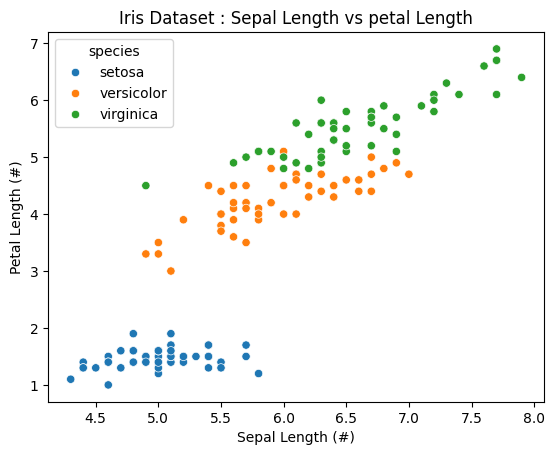

In [14]:
sns.scatterplot(
    data=iris,
    x="sepal_length",
    y="petal_length",
    hue="species"
)

plt.title("Iris Dataset : Sepal Length vs petal Length")
plt.xlabel("Sepal Length (#)")
plt.ylabel("Petal Length (#)")

plt.show()

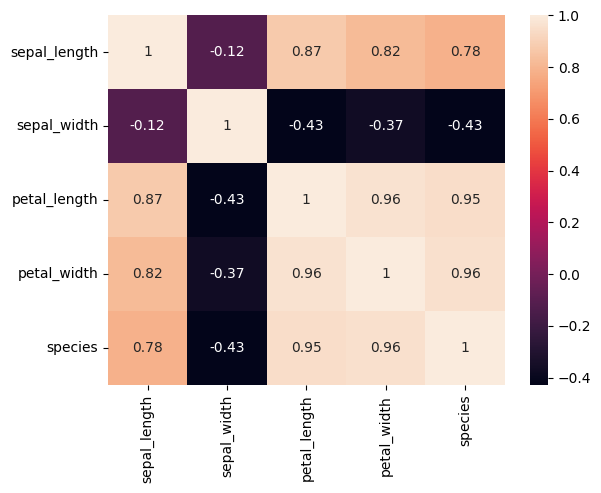

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

Correlation = df.corr(numeric_only=True)

sns.heatmap(Correlation, annot=True)

plt.show()

In [16]:
from sklearn.model_selection import train_test_split

# Define X and y
X = df.drop("species", axis=1)   # Features
y = df["species"]                # Target

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)


In [17]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
model = KNeighborsClassifier(n_neighbors=5)

# Train model
model.fit(X_train, y_train)

# Predict test data
y_pred = model.predict(X_test)

print("Predicted Values:")
print(y_pred)

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


In [18]:
new_data = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_data)

print("Predicted Class:", prediction)

Predicted Class: [0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [19]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy * 100, "%")

Accuracy: 100.0 %


In [20]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


First 5 Records:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Last 5 Records:
     sepal_length  sepal_width  petal_length  petal_width    species
145           6.7          3.0           5.2          2.3  virginica
146           6.3          2.5           5.0          1.9  virginica
147           6.5          3.0           5.2          2.0  virginica
148           6.2          3.4           5.4          2.3  virginica
149           5.9          3.0           5.1          1.8  virginica

Median:
sepal_length    5.80
sepal_width     3.00
petal_length    4.35
petal_width     1.30
dtype: float64

Minimum:
sepal_length    4.3
sepal_width     2.0
petal_leng

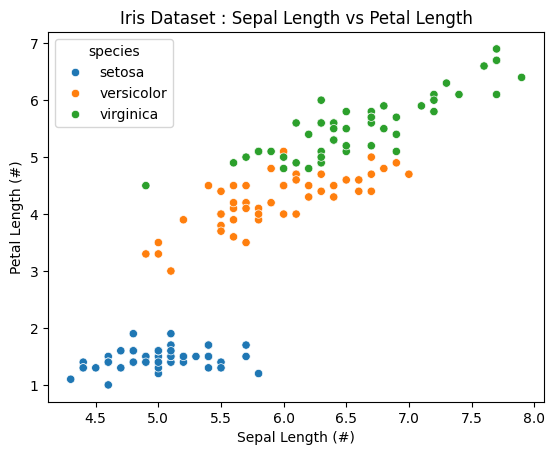

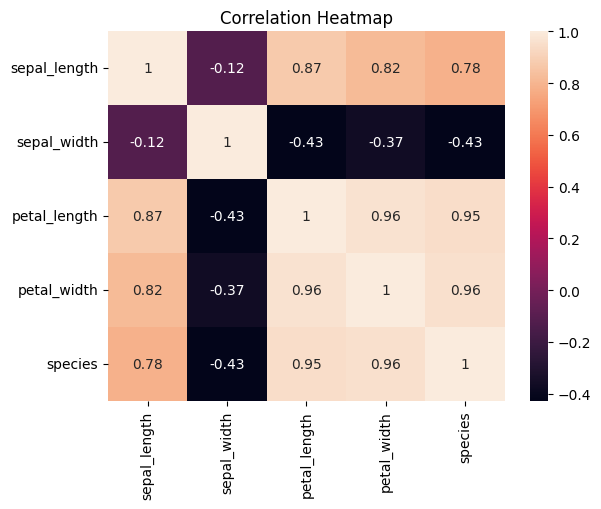


X_train shape: (120, 4)
X_test shape: (30, 4)
y_train shape: (120,)
y_test shape: (30,)

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted Class: [0]

Accuracy: 100.0 %

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


In [21]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix


# -----------------------------------
# 1. Load Iris Dataset
# -----------------------------------

iris = sns.load_dataset("iris")

df = pd.DataFrame(iris)

print("First 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())


# -----------------------------------
# 2. Statistical Analysis
# -----------------------------------

print("\nMedian:")
print(df.median(numeric_only=True))

print("\nMinimum:")
print(df.min(numeric_only=True))

print("\nStandard Deviation:")
print(df.std(numeric_only=True))


# -----------------------------------
# 3. Label Encoding
# -----------------------------------

le = LabelEncoder()

df["species"] = le.fit_transform(df["species"])

print("\nEncoded Dataset:")
print(df.head())


# -----------------------------------
# 4. Scatter Plot
# -----------------------------------

sns.scatterplot(
    data=iris,
    x="sepal_length",
    y="petal_length",
    hue="species"
)

plt.title("Iris Dataset : Sepal Length vs Petal Length")
plt.xlabel("Sepal Length (#)")
plt.ylabel("Petal Length (#)")

plt.show()


# -----------------------------------
# 5. Correlation Heatmap
# -----------------------------------

Correlation = df.corr(numeric_only=True)

sns.heatmap(Correlation, annot=True)

plt.title("Correlation Heatmap")

plt.show()


# -----------------------------------
# 6. Define X and y
# -----------------------------------

X = df.drop("species", axis=1)
y = df["species"]


# -----------------------------------
# 7. Train Test Split
# -----------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


# -----------------------------------
# 8. KNN Model
# -----------------------------------

model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)


# -----------------------------------
# 9. Prediction
# -----------------------------------

y_pred = model.predict(X_test)

print("\nPredicted Values:")
print(y_pred)


# -----------------------------------
# 10. Predict New Data
# -----------------------------------

new_data = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(new_data)

print("\nPredicted Class:", prediction)


# -----------------------------------
# 11. Accuracy
# -----------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy * 100, "%")


# -----------------------------------
# 12. Confusion Matrix
# -----------------------------------

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)